# Customer Engagement Analysis: Poisson Regression

**Independent data analytics project**  
*Exploratory analysis · Count regression · Model validation*

## Research question

Which customer profile characteristics are associated with how frequently customers visit a company's website?

The outcome is `NumWebVisitsMonth`, the number of website visits recorded in the last month. The project uses exploratory analysis and Poisson regression to study customer income and household composition.

**Approach:** The main model is intentionally interpretable. Results describe associations, not causes. A random holdout evaluates performance on other customers in this dataset; it is not a forecast for a future period.

## 1. Data and setup

The *Customer Personality Analysis* dataset contains customer demographics, household information, purchasing behaviour, campaign responses and monthly website visits. The original CSV is tab-separated.

Source: [Customer Personality Analysis — Kaggle](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis). The dataset description credits Dr. Omar Romero-Hernandez as the data provider.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.discrete.count_model import GeneralizedPoisson
from scipy.stats import chi2
from sklearn.model_selection import train_test_split, RepeatedKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance

DATA_PATH = Path("data/raw/marketing_campaign.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("marketing_campaign.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Place marketing_campaign.csv in data/raw/ or beside this notebook.")

df = pd.read_csv(DATA_PATH, sep="\t")
print(f"Loaded {df.shape[0]:,} customers and {df.shape[1]} variables.")

Loaded 2,240 customers and 29 variables.


## 2. Data quality and outcome

,check,result
0,Duplicate rows,0
1,Unique customer IDs,2240
2,Missing income values,24
3,Birth years before 1910,3
4,"Income above 300,000",1
5,Unparseable enrollment dates,0


,customers,mean_visits,median_visits,variance,minimum,maximum,zero_visits
0,2240,5.32,6.0,5.89,0,20,11


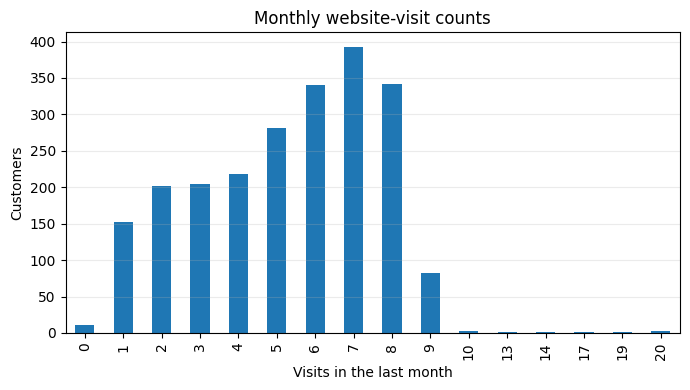

In [2]:
audit = pd.DataFrame({
    "check": [
        "Duplicate rows", "Unique customer IDs", "Missing income values",
        "Birth years before 1910", "Income above 300,000", "Unparseable enrollment dates"
    ],
    "result": [
        int(df.duplicated().sum()),
        int(df["ID"].nunique()),
        int(df["Income"].isna().sum()),
        int((df["Year_Birth"] < 1910).sum()),
        int((df["Income"] > 300_000).sum()),
        int(pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y", errors="coerce").isna().sum()),
    ]
})
display(audit)

visit = df["NumWebVisitsMonth"]
outcome = pd.DataFrame({
    "customers": [visit.count()],
    "mean_visits": [visit.mean()],
    "median_visits": [visit.median()],
    "variance": [visit.var()],
    "minimum": [visit.min()],
    "maximum": [visit.max()],
    "zero_visits": [(visit == 0).sum()],
})
display(outcome.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
visit.value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set(title="Monthly website-visit counts", xlabel="Visits in the last month", ylabel="Customers")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("figures/website_visit_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

The file has unique customer IDs and 24 missing income values. Three birth years are earlier than 1910, and one income value is unusually high. These records are retained in the raw data; model sensitivity is checked later.

The dataset does not identify a reliable reference date for calculating customer age. The main model therefore does not create an age variable from `Year_Birth`.

## 3. Exploratory relationships

Rank correlations are descriptive screens. Purchasing variables are shown for context, but are not used in the main model because they may overlap with the same customer activity being studied.

,variable,n,spearman_rho
0,Income,2216,-0.644
5,NumCatalogPurchases,2240,-0.536
9,MntMeatProducts,2240,-0.492
1,Kidhome,2240,0.482
6,NumStorePurchases,2240,-0.454
3,NumDealsPurchases,2240,0.398
8,Year_Birth,2240,0.131
2,Teenhome,2240,0.112
4,NumWebPurchases,2240,-0.097
7,Recency,2240,-0.022


,customers,mean_visits,median_visits
children_home,,,
0,638,3.48,3.0
1,1128,5.94,6.0
2,421,6.30,7.0
3,53,6.45,7.0


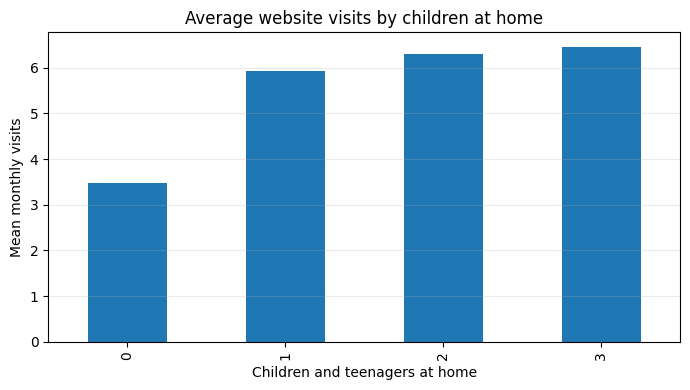

In [3]:
screen_cols = [
    "Income", "Kidhome", "Teenhome", "NumDealsPurchases", "NumWebPurchases",
    "NumCatalogPurchases", "NumStorePurchases", "Recency", "Year_Birth", "MntMeatProducts"
]
correlations = pd.DataFrame([
    {
        "variable": col,
        "n": df[[col, "NumWebVisitsMonth"]].dropna().shape[0],
        "spearman_rho": df[col].corr(df["NumWebVisitsMonth"], method="spearman"),
    }
    for col in screen_cols
]).sort_values("spearman_rho", key=lambda x: x.abs(), ascending=False)
display(correlations.round(3))

visits_by_children = df.assign(children_home=df["Kidhome"] + df["Teenhome"]).groupby("children_home")["NumWebVisitsMonth"].agg(
    customers="count", mean_visits="mean", median_visits="median"
)
display(visits_by_children.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
visits_by_children["mean_visits"].plot(kind="bar", ax=ax)
ax.set(title="Average website visits by children at home", xlabel="Children and teenagers at home", ylabel="Mean monthly visits")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("figures/visits_by_household_children.png", dpi=180, bbox_inches="tight")
plt.show()

Income and household composition show descriptive relationships with website visits. Purchase-channel counts and spending also correlate with visits, but may capture closely related behaviour rather than customer characteristics available before engagement occurs. The model below therefore focuses on **income** and **children/teenagers at home**.

## 4. Fit an interpretable Poisson model

An 80/20 split is made before imputation. Missing income is replaced with the training-set median only. Income is log-transformed; `children_home` combines `Kidhome` and `Teenhome`.

The Poisson model uses a log link:

\[\log\{E(Y\mid X)\}=eta_0+eta_1\log(1+	ext{income})+eta_2	ext{children\_home}.\]

HC3 robust standard errors are used for coefficient intervals and tests.

In [4]:
train_raw, test_raw = train_test_split(df, test_size=0.20, random_state=42)
income_median = train_raw["Income"].median()

def add_features(data, median_income):
    out = data.copy()
    out["log_income"] = np.log1p(out["Income"].fillna(median_income))
    out["children_home"] = out["Kidhome"] + out["Teenhome"]
    return out

train = add_features(train_raw, income_median)
test = add_features(test_raw, income_median)
FORMULA = "NumWebVisitsMonth ~ log_income + children_home"

poisson = smf.glm(FORMULA, data=train, family=sm.families.Poisson()).fit(cov_type="HC3")
print(f"Training customers: {len(train):,} | Test customers: {len(test):,}")
print(f"Income median used for imputation: {income_median:,.0f}")
print(f"Missing income imputed — train: {train_raw.Income.isna().sum()}, test: {test_raw.Income.isna().sum()}")

Training customers: 1,792 | Test customers: 448
Income median used for imputation: 50,965
Missing income imputed — train: 19, test: 5


## 5. Interpret the coefficients

An incidence rate ratio (IRR) above 1 indicates a higher expected visit count; below 1 indicates a lower expected count, holding the other model variable constant. For income, the comparison is a 10% increase from the training-sample median.

In [5]:
ci = poisson.conf_int()
income_step = np.log1p(income_median * 1.10) - np.log1p(income_median)

income_irr = np.exp(poisson.params["log_income"] * income_step)
income_ci = np.exp(ci.loc["log_income"].to_numpy() * income_step)
children_irr = np.exp(poisson.params["children_home"])
children_ci = np.exp(ci.loc["children_home"].to_numpy())

effects = pd.DataFrame([
    ["10% higher income near training median", income_irr, income_ci[0], income_ci[1], poisson.pvalues["log_income"]],
    ["One additional child or teenager at home", children_irr, children_ci[0], children_ci[1], poisson.pvalues["children_home"]],
], columns=["comparison", "IRR", "CI lower", "CI upper", "HC3 p-value"])
effects["relative change"] = (effects["IRR"] - 1) * 100
effects["95% CI"] = effects.apply(lambda r: f"{r['CI lower']:.3f}–{r['CI upper']:.3f}", axis=1)
effects["HC3 p-value"] = effects["HC3 p-value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")
display(effects[["comparison", "IRR", "95% CI", "relative change", "HC3 p-value"]].round({"IRR": 3, "relative change": 1}))

,comparison,IRR,95% CI,relative change,HC3 p-value
0,10% higher income near training median,0.960,0.956–0.965,-4.0,<0.001
1,One additional child or teenager at home,1.213,1.185–1.241,21.3,<0.001


The fitted model estimates an inverse association between income and monthly website visits, and a positive association with the number of children or teenagers at home. These are adjusted associations in this sample; they do not explain why customers browse more often.

## 6. Check whether added predictors are worthwhile

All specification checks use the training sample. Likelihood-ratio tests compare nested Poisson models fitted to the same customers. The simpler two-predictor model remains the reference.

In [6]:
train_specs = train.copy()
train_specs["birth_decade"] = (train_specs["Year_Birth"] - 1970) / 10
rare_statuses = train_specs["Marital_Status"].value_counts().loc[lambda x: x < 20].index
train_specs["Marital_group"] = train_specs["Marital_Status"].where(
    ~train_specs["Marital_Status"].isin(rare_statuses), "Other / rare"
)

base_mle = smf.glm(FORMULA, data=train_specs, family=sm.families.Poisson()).fit()
forms = {
    "Add birth year": FORMULA + " + birth_decade",
    "Separate children and teenagers": "NumWebVisitsMonth ~ log_income + Kidhome + Teenhome",
    "Add education and marital status": FORMULA + " + C(Education, Treatment(reference='Graduation')) + C(Marital_group, Treatment(reference='Married'))",
    "Add recency and complaint": FORMULA + " + Recency + Complain",
}

spec_rows = []
for label, formula in forms.items():
    candidate = smf.glm(formula, data=train_specs, family=sm.families.Poisson()).fit()
    df_added = int(candidate.df_model - base_mle.df_model)
    lr_stat = 2 * (candidate.llf - base_mle.llf)
    p_value = chi2.sf(lr_stat, df_added)
    spec_rows.append([label, candidate.aic, df_added, lr_stat, p_value])

specification = pd.DataFrame(spec_rows, columns=["additional terms", "AIC", "df added", "LR statistic", "LR p-value"])
display(specification.round(3))

,additional terms,AIC,df added,LR statistic,LR p-value
0,Add birth year,7478.413,1,3.008,0.083
1,Separate children and teenagers,7481.113,1,0.308,0.579
2,Add education and marital status,7494.219,9,3.201,0.956
3,Add recency and complaint,7481.286,2,2.134,0.344


The extra specifications are useful checks, not an invitation to keep adding variables. Birth year gives only a modest improvement in training fit and has no clean age interpretation without a reference date. Separating children from teenagers does not improve fit. Education and marital status, and recency and complaint status, also do not provide convincing joint improvements. The two-predictor model is retained for clarity.

## 7. Check the Poisson variance assumption

For a well-fitting Poisson mean/variance relationship, Pearson chi-square and residual deviance divided by residual degrees of freedom are often assessed against 1. Values below 1 suggest underdispersion.

In [7]:
poisson_mle = smf.glm(FORMULA, data=train, family=sm.families.Poisson()).fit()
generalized = GeneralizedPoisson.from_formula(FORMULA, data=train, p=1).fit(
    disp=0, maxiter=500, cov_type="HC0"
)

dispersion = pd.DataFrame({
    "diagnostic": ["Pearson chi-square / residual df", "Residual deviance / residual df"],
    "value": [poisson_mle.pearson_chi2 / poisson_mle.df_resid, poisson_mle.deviance / poisson_mle.df_resid],
})
display(dispersion.round(3))
print(f"Generalized Poisson converged: {generalized.mle_retvals['converged']}")
print(f"Generalized Poisson alpha: {generalized.params['alpha']:.3f} | AIC: {generalized.aic:.1f}")
print(f"Poisson AIC: {poisson_mle.aic:.1f}")

,diagnostic,value
0,Pearson chi-square / residual df,0.710
1,Residual deviance / residual df,0.776


Generalized Poisson converged: True
Generalized Poisson alpha: -0.161 | AIC: 7385.9
Poisson AIC: 7479.4


The conditional dispersion ratios are below 1, indicating potential underdispersion. The generalized Poisson model estimates a negative dispersion parameter and improves in-sample AIC, but its held-out prediction errors should also be checked before preferring the more complex distribution.

## 8. Evaluate on held-out customers

The 448 test customers are not used to fit the models or choose predictors. An intercept-only benchmark predicts the training-set mean for everyone.

,MAE,RMSE,Poisson deviance
Intercept-only baseline,1.979,2.338,1.174
Poisson,1.546,1.837,0.726
Generalized Poisson,1.547,1.836,0.727


Poisson MAE improvement over baseline: 21.9%


,customers,observed_visits,predicted_visits
0,45,2.16,3.27
1,45,2.53,3.50
2,45,4.24,3.99
3,44,5.32,4.46
4,45,5.91,4.79
5,45,6.33,5.19
6,44,6.48,5.56
7,45,6.76,6.03
8,45,6.96,6.57
9,45,6.87,7.75


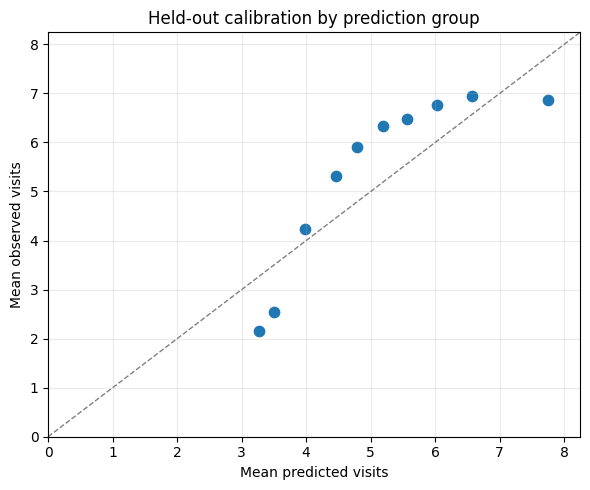

In [8]:
def score(actual, predicted):
    predicted = np.clip(np.asarray(predicted), 1e-8, None)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "Poisson deviance": mean_poisson_deviance(actual, predicted),
    }

actual = test["NumWebVisitsMonth"]
predictions = {
    "Intercept-only baseline": np.repeat(train["NumWebVisitsMonth"].mean(), len(test)),
    "Poisson": poisson.predict(test),
    "Generalized Poisson": generalized.predict(test),
}
performance = pd.DataFrame({name: score(actual, pred) for name, pred in predictions.items()}).T
display(performance.round(3))

improvement = 100 * (1 - performance.loc["Poisson", "MAE"] / performance.loc["Intercept-only baseline", "MAE"])
print(f"Poisson MAE improvement over baseline: {improvement:.1f}%")

calibration = pd.DataFrame({"actual": actual, "predicted": predictions["Poisson"]})
calibration["group"] = pd.qcut(calibration["predicted"], q=10, duplicates="drop")
calibration = calibration.groupby("group", observed=True).agg(
    customers=("actual", "size"), observed_visits=("actual", "mean"), predicted_visits=("predicted", "mean")
).reset_index(drop=True)

display(calibration.round(2))
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(calibration["predicted_visits"], calibration["observed_visits"], s=55)
limit = max(calibration["predicted_visits"].max(), calibration["observed_visits"].max()) + 0.5
ax.plot([0, limit], [0, limit], "--", color="grey", linewidth=1)
ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="Mean predicted visits", ylabel="Mean observed visits",
       title="Held-out calibration by prediction group")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("figures/heldout_calibration.png", dpi=180, bbox_inches="tight")
plt.show()

The Poisson model improves on the intercept-only benchmark, but the generalized Poisson model has nearly identical held-out errors. Calibration is not perfect, so the model is best presented as an interpretable baseline rather than a deployment-ready prediction system.

## 9. Cross-validation and sensitivity

Repeated cross-validation is run only within the training sample. Income imputation is recalculated from each fold's training portion. A separate sensitivity check removes the single highest-income training observation.

In [9]:
cv_rows = []
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=123)
for fold_train_idx, fold_valid_idx in cv.split(train_raw):
    fold_train_raw = train_raw.iloc[fold_train_idx].copy()
    fold_valid_raw = train_raw.iloc[fold_valid_idx].copy()
    fold_median = fold_train_raw["Income"].median()
    fold_train = add_features(fold_train_raw, fold_median)
    fold_valid = add_features(fold_valid_raw, fold_median)
    fitted = smf.glm(FORMULA, data=fold_train, family=sm.families.Poisson()).fit()
    cv_rows.append({
        "Poisson MAE": mean_absolute_error(fold_valid["NumWebVisitsMonth"], fitted.predict(fold_valid)),
        "Baseline MAE": mean_absolute_error(
            fold_valid["NumWebVisitsMonth"],
            np.repeat(fold_train["NumWebVisitsMonth"].mean(), len(fold_valid))
        ),
    })
cv_summary = pd.DataFrame(cv_rows).agg(["mean", "std"]).T
cv_summary.columns = ["Mean", "SD"]
display(cv_summary.round(3))

sensitivity_sample = train_raw.loc[train_raw["Income"].isna() | (train_raw["Income"] <= 300_000)].copy()
sensitivity_median = sensitivity_sample["Income"].median()
sensitivity_data = add_features(sensitivity_sample, sensitivity_median)
sensitivity_fit = smf.glm(FORMULA, data=sensitivity_data, family=sm.families.Poisson()).fit(cov_type="HC3")
sensitivity_step = np.log1p(sensitivity_median * 1.10) - np.log1p(sensitivity_median)

sensitivity = pd.DataFrame([
    ["All training customers", np.exp(poisson.params["log_income"] * income_step), np.exp(poisson.params["children_home"])],
    ["Exclude income above 300,000", np.exp(sensitivity_fit.params["log_income"] * sensitivity_step), np.exp(sensitivity_fit.params["children_home"])],
], columns=["sample", "income IRR for 10% increase", "household IRR per additional child/teen"])
display(sensitivity.round(3))

,Mean,SD
Poisson MAE,1.548,0.049
Baseline MAE,2.006,0.055


,sample,income IRR for 10% increase,household IRR per additional child/teen
0,All training customers,0.96,1.213
1,"Exclude income above 300,000",0.96,1.212


## 10. Conclusion and limitations

### Main findings

- A 10% higher income near the training-sample median is associated with approximately **4.0% fewer expected monthly website visits** (IRR about 0.960; HC3 95% CI about 0.956–0.965).
- One additional child or teenager at home is associated with approximately **21.3% more expected monthly visits** (IRR about 1.213; HC3 95% CI about 1.185–1.241).
- On the held-out customers, the Poisson model reduces MAE by about **22%** versus the intercept-only benchmark. Repeated cross-validation gives a similar pattern.
- Conditional dispersion is below 1. The generalized Poisson alternative captures this pattern better in-sample, but does not materially improve held-out prediction errors.

### Business interpretation

Customer income and household composition may help describe differences in online browsing frequency. A business could use these patterns to formulate customer-engagement hypotheses, but this dataset does not show why customers browse more or whether a particular marketing action would change behaviour.

### Limitations

- The data is observational and does not establish causation.
- The exact reference date for monthly website visits is not documented.
- Income units are not specified, so effects are reported as percentage changes rather than currency amounts.
- The holdout and cross-validation assess performance across customers in this dataset, not future-period performance.
- The model uses two customer characteristics and does not capture all drivers of browsing behaviour.
- Calibration is imperfect, and the Poisson variance assumption is not exact.

This project demonstrates an interpretable count-regression workflow, not a production-ready customer scoring system.

## Reproducibility

Run this notebook from top to bottom. Place `marketing_campaign.csv` in `data/raw/`. The fixed random seeds make the holdout and cross-validation splits reproducible.